## SPRINT 7 - PROJETO - COLETA E ARMAZENAMENTO DE DAODOS (SQL)

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

In [10]:
df_companies = pd.read_csv('project_sql_result_01.csv')
df_neighborhoods = pd.read_csv('project_sql_result_04.csv')
df_trips = pd.read_csv('project_sql_result_07.csv')

In [11]:
print("--- Informações de empresas de táxi ---")
print(df_companies.info())
print(df_companies.describe())
print(df_companies.head(), "\n")

--- Informações de empresas de táxi ---
<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   company_name  64 non-null     str  
 1   trips_amount  64 non-null     int64
dtypes: int64(1), str(1)
memory usage: 2.5 KB
None
       trips_amount
count     64.000000
mean    2145.484375
std     3812.310186
min        2.000000
25%       20.750000
50%      178.500000
75%     2106.500000
max    19558.000000
                      company_name  trips_amount
0                        Flash Cab         19558
1        Taxi Affiliation Services         11422
2                 Medallion Leasin         10367
3                       Yellow Cab          9888
4  Taxi Affiliation Service Yellow          9299 



In [12]:
print("--- Informações de destinos (bairros) ---")
print(df_neighborhoods.info())
print(df_neighborhoods.describe())
print(df_neighborhoods.head(), "\n")

--- Informações de destinos (bairros) ---
<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     str    
 1   average_trips          94 non-null     float64
dtypes: float64(1), str(1)
memory usage: 2.6 KB
None
       average_trips
count      94.000000
mean      599.953728
std      1714.591098
min         1.800000
25%        14.266667
50%        52.016667
75%       298.858333
max     10727.466667
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000 



In [13]:
top_10_neighborhoods = (
    df_neighborhoods.sort_values(by="average_trips", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("--- Top 10 bairros com mais destinos ---")
print(top_10_neighborhoods, "\n")

--- Top 10 bairros com mais destinos ---
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667 



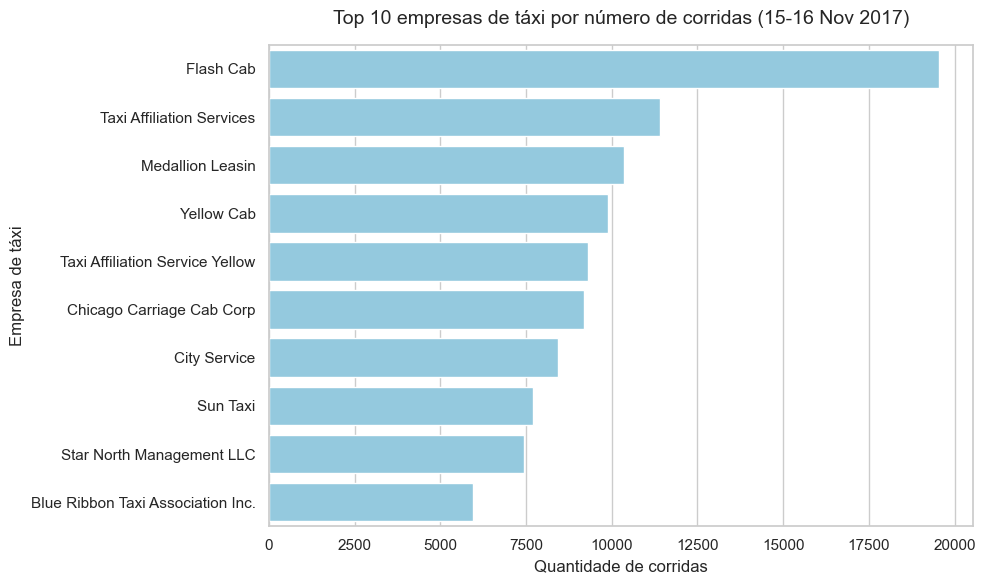

In [14]:
sns.set_theme(style="whitegrid")
top_companies = (
    df_companies.sort_values(by="trips_amount", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_companies, x="trips_amount", y="company_name", color="skyblue")

plt.title(
    "Top 10 empresas de táxi por número de corridas (15-16 Nov 2017)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Quantidade de corridas")
plt.ylabel("Empresa de táxi")
plt.tight_layout()
plt.show()

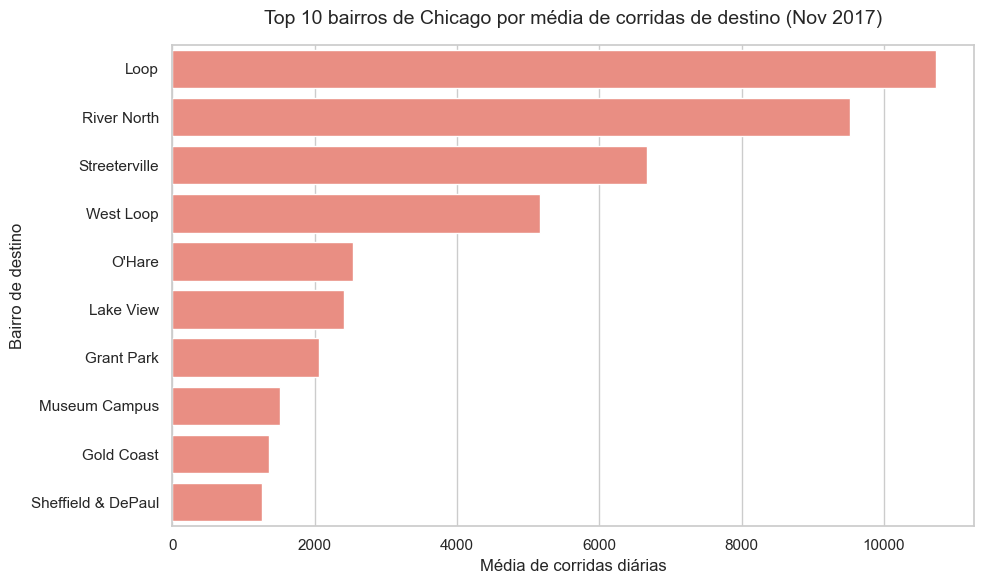

In [15]:
top_10_neighborhoods = (
    df_neighborhoods.sort_values(by="average_trips", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_neighborhoods,
    x="average_trips",
    y="dropoff_location_name",
    color="salmon",
)
plt.title(
    "Top 10 bairros de Chicago por média de corridas de destino (Nov 2017)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Média de corridas diárias")
plt.ylabel("Bairro de destino")
plt.tight_layout()
plt.show()

Conclusões: A análise do mercado de táxis em Chicago aponta a Flash Cab como líder isolada com quase 20.000 corridas em dois dias, seguida pela Taxi Affiliation Services com 11.500 e outras empresas mantendo uma média entre 7.000 e 10.000. Essa forte concentração no topo sugere que a Flash Cab domina devido ao tamanho da frota ou contratos corporativos. Em termos de destinos, os bairros centrais Loop e River North lideram com folga devido ao forte apelo comercial, turístico e financeiro, seguidos por Streeterville, West Loop e pelo aeroporto O'Hare, que gera viagens mais longas e valiosas. Diante disso, o cenário indica que a Zuber deve evitar a concorrência direta por volume total com a líder e focar em diferenciação de serviço, posicionando estrategicamente sua frota e oferecendo incentivos para motoristas nessas zonas de alta demanda no centro e no fluxo para o aeroporto.

In [16]:
good_weather_trips = df_trips[df_trips["weather_conditions"] == "Good"][
    "duration_seconds"
]
bad_weather_trips = df_trips[df_trips["weather_conditions"] == "Bad"][
    "duration_seconds"
]

print(f"Média de duração em dias 'Good': {good_weather_trips.mean():.2f} segundos")
print(f"Média de duração em dias 'Bad': {bad_weather_trips.mean():.2f} segundos")

Média de duração em dias 'Good': 1999.68 segundos
Média de duração em dias 'Bad': 2427.21 segundos


In [17]:
alpha = 0.05
results = stats.ttest_ind(
    good_weather_trips, bad_weather_trips, equal_var=False
)

print(f"p-value: {results.pvalue}")

if results.pvalue < alpha:
    print(
        "Rejeitamos a hipótese nula: A duração média das corridas muda de forma significante nos sábados chuvosos."
    )
else:
    print(
        "Não podemos rejeitar a hipótese nula: Não há evidências estatísticas de que a duração média das corridas mude nos sábados chuvosos."
    )

p-value: 6.738994326108734e-12
Rejeitamos a hipótese nula: A duração média das corridas muda de forma significante nos sábados chuvosos.


A formulação das hipóteses estatísticas baseia-se no princípio do "status quo", onde a Hipótese Nula ($H_0$) assume que a chuva não altera o tempo de viagem, definindo que a duração média das corridas do Loop para o Aeroporto O'Hare nos sábados chuvosos é igual à dos sábados de clima bom ($M_1 = M_2$). Já a Hipótese Alternativa ($H_1$) busca provar um impacto real e, por questionar se a duração simplesmente muda, configura um teste bicaudal que estabelece que as médias são diferentes ($M_1 \neq M_2$).Para testar essa relação, utilizou-se o Teste t de Student para duas amostras independentes na variação de Welch, avaliado pelo $p\text{-value}$ com nível de significância ($\alpha$) de 5%. A escolha do teste justifica-se por comparar médias de uma variável contínua entre dois grupos independentes, já que os sábados de sol e chuva não têm relação direta. A variação de Welch foi aplicada porque, em cenários reais de tráfego, o volume e a variabilidade das corridas mudam conforme o clima, gerando amostras com variâncias diferentes. Por fim, definiu-se o $\alpha$ em 0,05 como uma margem tolerável que exige 95% de certeza para afirmar que o clima gera impacto. Assim, se o $p\text{-value}$ for menor que o $\alpha$, a chance de a diferença ser fruto do acaso é inferior a 5%, o que torna o resultado estatisticamente significante e leva à rejeição da hipótese nula.